In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("Wholesale customers data.csv")

In [7]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [8]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [9]:
df.shape

(440, 8)

In [10]:
df.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

In [11]:
df.info

<bound method DataFrame.info of      Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0          2       3  12669   9656     7561     214              2674   
1          2       3   7057   9810     9568    1762              3293   
2          2       3   6353   8808     7684    2405              3516   
3          1       3  13265   1196     4221    6404               507   
4          2       3  22615   5410     7198    3915              1777   
..       ...     ...    ...    ...      ...     ...               ...   
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
0          1338  
1          1776  
2          7844  
3          1788  
4

In [12]:
df.describe

<bound method NDFrame.describe of      Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0          2       3  12669   9656     7561     214              2674   
1          2       3   7057   9810     9568    1762              3293   
2          2       3   6353   8808     7684    2405              3516   
3          1       3  13265   1196     4221    6404               507   
4          2       3  22615   5410     7198    3915              1777   
..       ...     ...    ...    ...      ...     ...               ...   
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
0          1338  
1          1776  
2          7844  
3          1788  

In [13]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
features=["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]
X=df[features].copy()

display(X.head())
print("Number of records used for clustering:",len(X))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Number of records used for clustering: 440


In [16]:
#plot all graphs

In [17]:
# Standardize the six spending features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [18]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features,index=X.index)

In [19]:
print("First five Scaled Record")
display(X_scaled_df)

First five Scaled Record


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347
...,...,...,...,...,...,...
435,1.401312,0.848446,0.850760,2.075222,-0.566831,0.241091
436,2.155293,-0.592142,-0.757165,0.296561,-0.585519,0.291501
437,0.200326,1.314671,2.348386,-0.543380,2.511218,0.121456
438,-0.135384,-0.517536,-0.602514,-0.419441,-0.569770,0.213046


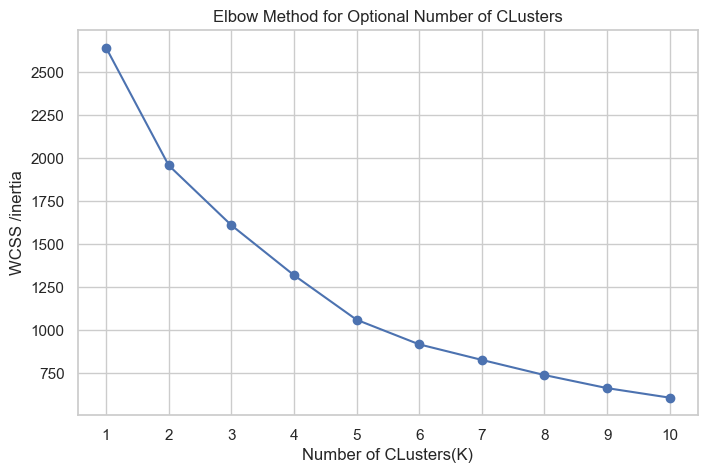

In [20]:
wcss=[]
k_values = range(1,11)

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state=42,
        n_init = 10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.title("Elbow Method for Optional Number of CLusters")
plt.xlabel("Number of CLusters(K)")
plt.ylabel("WCSS /inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [21]:
silhouette_values = []

for k in range(2,11):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters" : list(range(2,11)),
    "Silhouette Score" : silhouette_values
})

display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [22]:
suggested_k = int(
    silhouette_table.loc[
    silhouette_table["Silhouette Score"].idxmax(),
    "Number of Clusters"
    ]
)
print("k Suggested by the highest silhouette score:",suggested_k)


k Suggested by the highest silhouette score: 3


In [23]:
K=suggested_k
kmeans_model = KMeans(n_clusters = K,random_state=42,n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [24]:
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering computed.")
print("\nn Number of Customers in each CLuster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\n Sample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering computed.

n Number of Customers in each CLuster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

 Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [25]:
# Build the Hierarchical Clustering Model
hierarchical_model= AgglomerativeClustering(
    n_clusters =K,
    linkage="ward",
    metric = "euclidean"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [26]:
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical Clustering Completed")
print("\nNumber of customers in each cluster:")

print(
    df_hierarchical["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nSample record with cluster labels:")
display(df_hierarchical.head())

Hierarchical Clustering Completed

Number of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample record with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


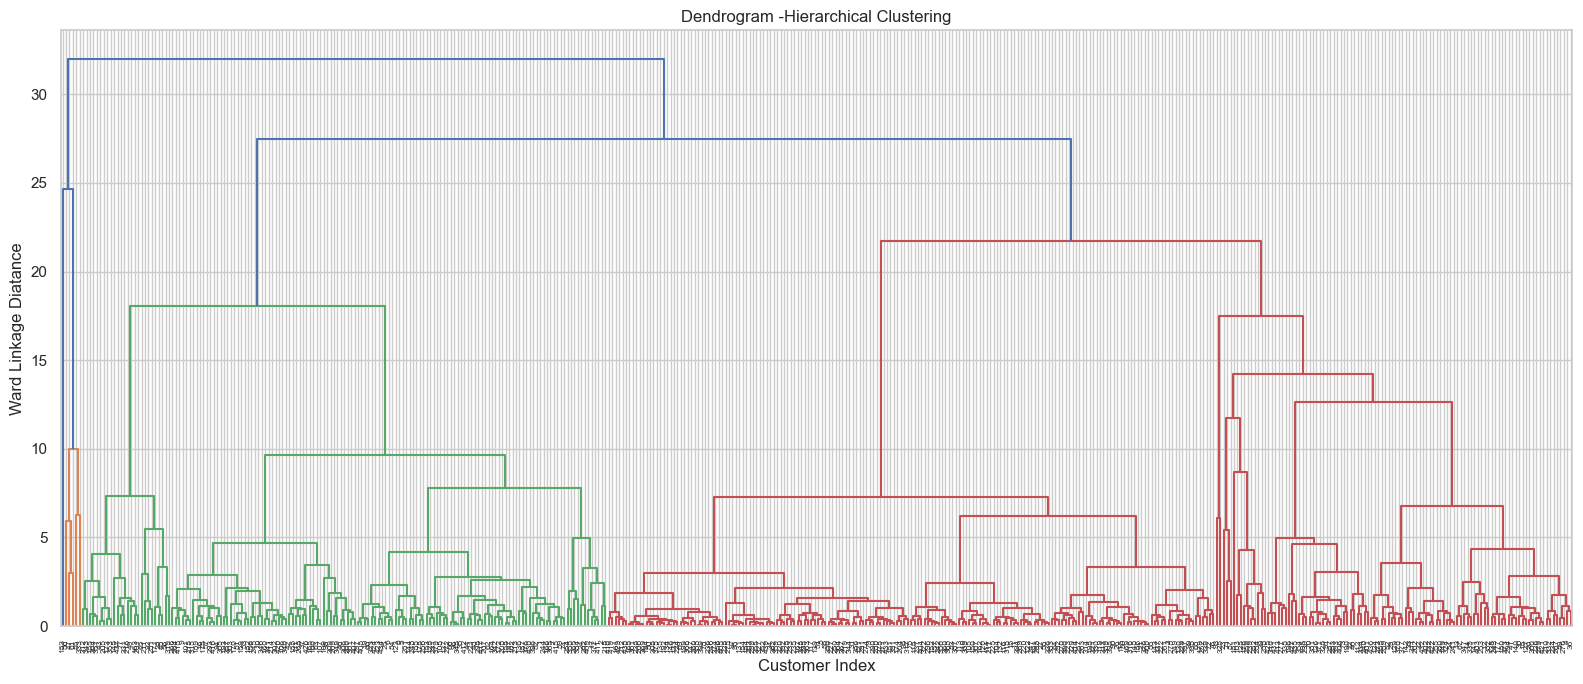

In [27]:
# Dendogram
Z = linkage(X_scaled,method = "ward",metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)

plt.title("Dendrogram -Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Diatance")
plt.tight_layout()
plt.show()

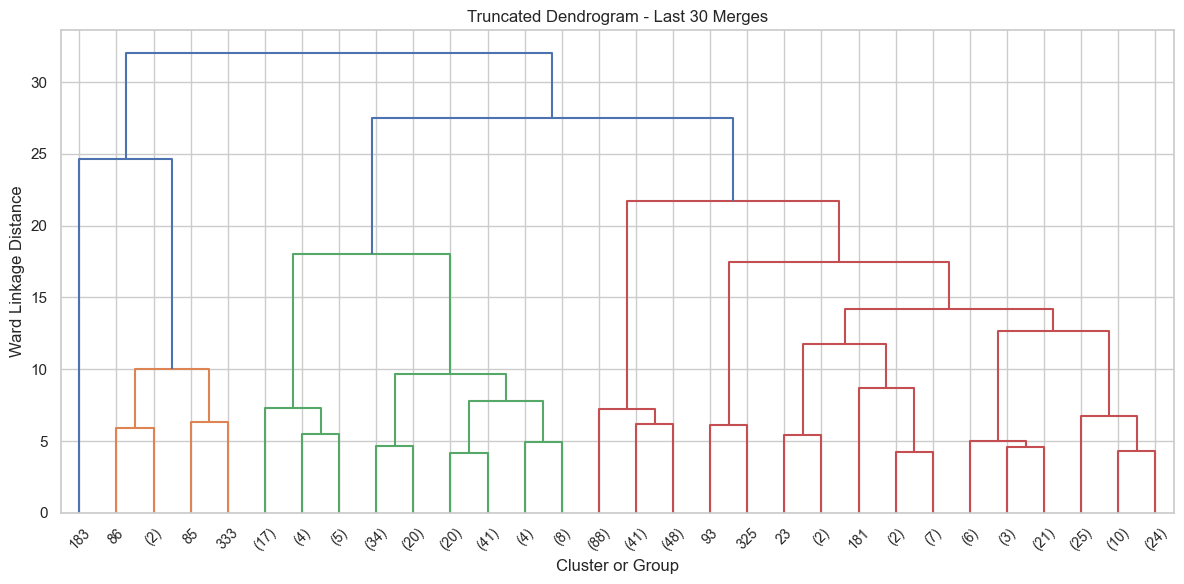

In [28]:
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=45)

plt.title("Truncated Dendrogram - Last 30 Merges")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


In [29]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Clustering": kmeans_labels.astype(str),
    "Hierarchical_Cluster": hierarchical_labels.astype(str)
})


Variance explained by the two PCA components: 72.46 %


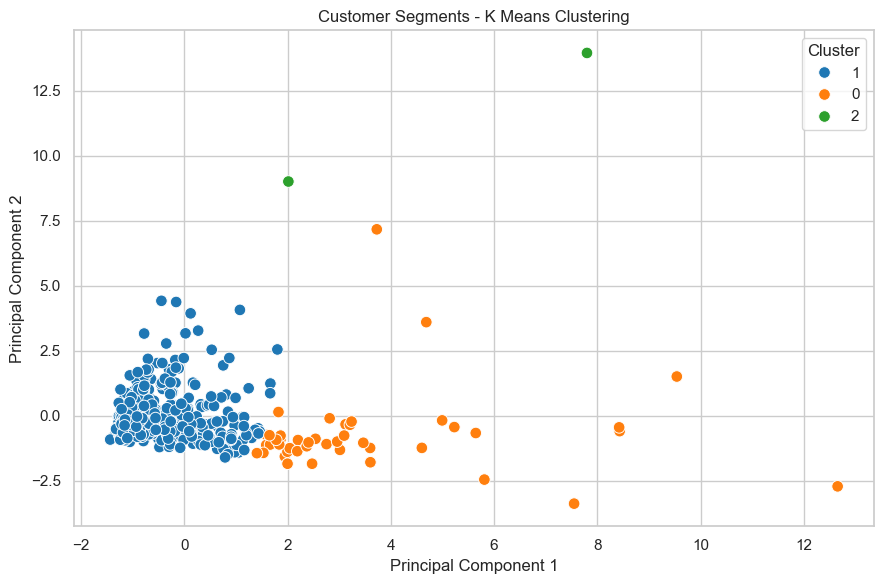

In [30]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans_Clustering", palette="tab10", s=70)

plt.title("Customer Segments - K Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


In [31]:
def evaluate_clustering(X_data,labels,model_name):
    return{
        "Algorithm":model_name,
        "Number of Clusters": len(np.unique(labels)),
    "Silhouette Score": silhouette_score(X_data,labels),
    "Devies-Bouldin Score": devies_bouldin_score(X_data,labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_data,labels)
    }

cluster_size = pd.DataFrame({
    "KMeans": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster size")
display(cluster_size)

In [32]:
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] =kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster")[features].mean().round(2)

print("Average spending profit of K-Means clusters:")
display(kmeans_means)

Average spending profit of K-Means clusters:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00


In [33]:
cluster_distribution = pd.DataFrame({
    "Cluster Count": pd.Series(kmeans_labels).value_counts().sort_index()
})

cluster_distribution["Percentage"] = (
    cluster_distribution["Cluster Count"]
    / len(df) * 100
).round(2)

print("K-Means customer distribution:")
display(cluster_distribution)


K-Means customer distribution:


,Cluster Count,Percentage
0,45,10.23
1,393,89.32
2,2,0.45


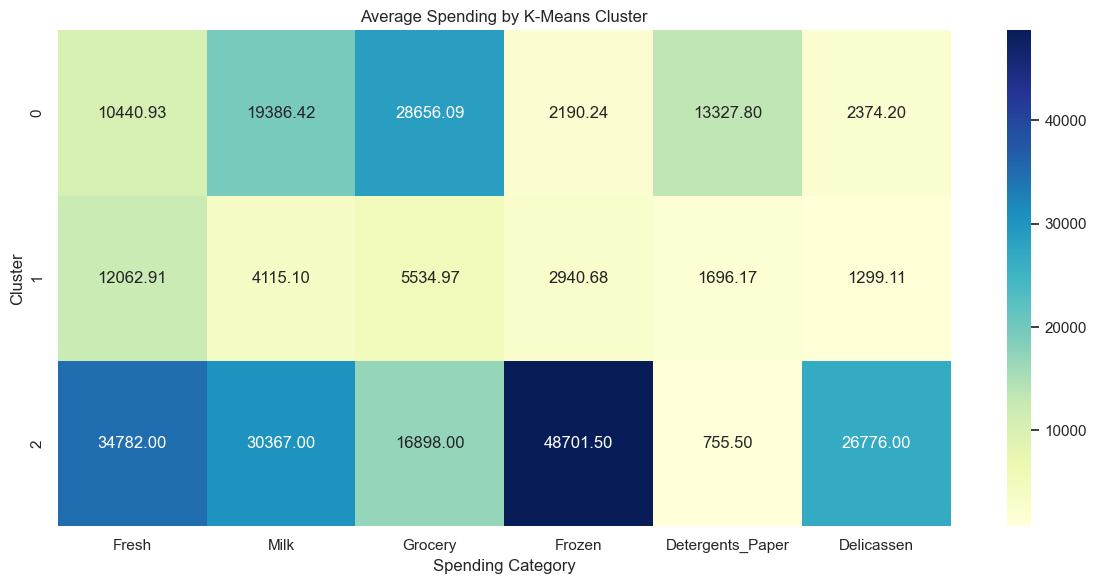

In [34]:
plt.figure(figsize=(12, 6))
sns.heatmap(kmeans_means, annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Average Spending by K-Means Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
channel_mix = pd.crosstab(
    df["Channel"],
    kmeans_labels,
    normalize="columns"
) * 100

channel_mix.columns = [
    f"Cluster {c}" for c in channel_mix.columns
]

print("Channel composition within each K-Mean cluster")
display(channel_mix)

Channel composition within each K-Mean cluster


,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.222222,75.063613,100.0
2,97.777778,24.936387,0.0
